17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 54s 165ms/step - accuracy: 0.7735 - loss: 0.4618 - val_accuracy: 0.8312 - val_loss: 0.4203
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 49s 158ms/step - accuracy: 0.8802 - loss: 0.2961 - val_accuracy: 0.8488 - val_loss: 0.3618
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 53s 169ms/step - accuracy: 0.9239 - loss: 0.2028 - val_accuracy: 0.8646 - val_loss: 0.3708
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 51s 162ms/step - accuracy: 0.9465 - loss: 0.1527 - val_accuracy: 0.8656 - val_loss: 0.4316
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 161ms/step - accuracy: 0.9566 - loss: 0.1249 - val_accuracy: 0.8476 - val_loss: 0.3935
782/782 ━━━━━━━━━━━━━━━━━━━━ 25s 31ms/step - accuracy: 0.8462 - loss: 0.3904
Test Accuracy: 0.8462399840354919


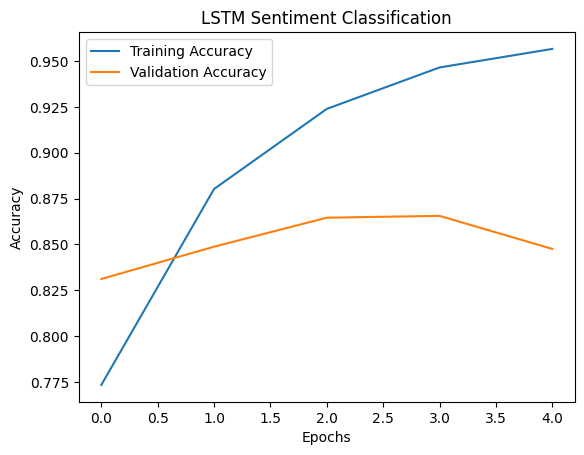

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# Load IMDB dataset
vocab_size = 10000
max_length = 200

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=vocab_size)

# Padding
X_train = pad_sequences(X_train, maxlen=max_length)
X_test = pad_sequences(X_test, maxlen=max_length)

# Build LSTM model
model = Sequential([
    Embedding(vocab_size, 64),
    LSTM(64),
    Dense(1, activation='sigmoid')
])

# Compile model
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

# Train model
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

# Evaluate model
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", accuracy)

# Plot accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('LSTM Sentiment Classification')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()